<a href="https://colab.research.google.com/github/erickcorrea3092/Antimalaria_QSAR/blob/main/1_Olaf_in_vitro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Código creado por el Dr. Erick Correa Padilla

FES Zaragoza UNAM.


Este código está para ayudarte a predecir propiedades de nuevas sustancias, úsalo con cuidado.





# ANTECEDENTES
Instala las versiones más recientes de numpy y pandas.

Avertencia
Por cuestiones de actualización de numpy es necesario correr la primer celda, por lo tanto `a=True` una vez que haya terminado de ejecutar es necesario reiniciar sesion (ctrl+ M.) y posteriormente ejecutar a partir de la segunda celda en adelante, la primer celda ya no se debe ejecutar, por lo que `a=False`

In [1]:
import sys
import numpy as np

print("Python:", sys.version)
print("NumPy:", np.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3


In [2]:
import scipy
import sklearn

print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

print("NUMPY + SCIPY + SKLEARN OK")

SciPy: 1.16.3
Scikit-learn: 1.6.1
NUMPY + SCIPY + SKLEARN OK


In [3]:
try:
    import umap
    print("UMAP:", umap.__version__)
    print("UMAP OK")
except Exception as e:
    print("ERROR UMAP:")
    print(type(e).__name__, e)

UMAP: 0.5.12
UMAP OK


# IMPORTAR LIBRERIAS



Bibliotecas a utilizar

- rdkit: Para manipulación de estructuras moleculares, cálculos de descriptores básicos

- mordred: Para descriptores moleculares

- molplotly: Para visualización de moléculas en gráficos interactivos

In [4]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      ! pip install rdkit
      pbar.update(30)
      ! pip install mordredcommunity
      pbar.update(60)
      ! pip install molplotly
      !pip install umap-learn
      pbar.update(100)


  0%|          | 0/100 [00:00<?, ?it/s]

In [5]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      import numpy as np
      import pandas as pd
      import seaborn as sns
      from mordred import Calculator, descriptors
      from dash import Dash, dcc, html, Input, Output
      #from tqdm.auto import tqdm, trange
      from matplotlib import pyplot as plt
      import molplotly
      import plotly.graph_objects as go
      import plotly.express as px
      pbar.update(50)
      from rdkit.Chem import AllChem
      from rdkit import Chem
      from rdkit.Chem import Descriptors
      from rdkit.ML.Descriptors import MoleculeDescriptors
      from rdkit.ML.Cluster import Butina
      from rdkit import DataStructs
      from rdkit.Chem import PandasTools
      import umap
      pbar.update(80)
      import sklearn
      from sklearn.svm import SVR, OneClassSVM
      from sklearn.pipeline import Pipeline
      from sklearn.decomposition import PCA
      from sklearn.ensemble import RandomForestRegressor
      from sklearn.model_selection import KFold, StratifiedShuffleSplit
      from sklearn.preprocessing import StandardScaler
      from sklearn.feature_selection import SelectFromModel, VarianceThreshold
      from sklearn.impute import SimpleImputer
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

## Auxiliares

Se definen clases y funciones auxiliares que nos van a servir más adelante.

In [6]:
# función de Culsterificación
def TaylorButina_Cluster(fpts, distThresh = 0.5):
    # Genera la matriz de distancia
    dist_matrix = []
    nfpts = len(fpts)
    for i in tqdm.notebook.tqdm(range(1,nfpts)):
        # generate Tanimoto similary
        Tanimoto_coefficients = DataStructs.BulkTanimotoSimilarity(fpts[i],fpts[:i])
        dist_matrix.extend([1 - j for j in Tanimoto_coefficients])
    #Cluster the Tanimoto scores using Butina:
    clusters = Butina.ClusterData(dist_matrix, nfpts, distThresh, isDistData=True)
    cluster_id_list = [0] * nfpts
    for idx,cluster in enumerate(clusters,1):
        for member in cluster:
            cluster_id_list[member] = idx
    return cluster_id_list

In [7]:
# función que regresa el puntaje de validación (score)
def score_cv(model, x, y, metrics="r2"):
    res = sklearn.model_selection.cross_validate(pipeline,
                                                 x_train, y,
                                                 scoring=metrics,
                                                 cv=CV_SPLITTER, n_jobs=-1)
    if isinstance(metrics, str):
        return np.mean(res["test_score"])
    return {metric: np.mean(res[f"test_{metric}"]) for metric in metrics}

In [8]:
# Regresa un dataframe con datos generales de un entrenamiento completo
# metric: la metrica a usar para evaluar
def validate_summary(metric):
    scorer = sklearn.metrics.get_scorer(metric)
    df = pd.DataFrame(index=[metric], data={
        "train": scorer(pipeline, x_train, y_train),
        "cv": score_cv(pipeline, x_train, y_train, metrics=metric),
        "test": scorer(pipeline, x_test, y_test),
    })
    return df

In [9]:
# clase que nos dice si hay elementos afuera del dominio de aplicación usando el método de leverage
class LeverageMethod(sklearn.base.BaseEstimator):
    def fit(self, x, y=None):
        self.normal_mat = np.linalg.inv(x.T @ x)
        self.n_samples = x.shape[0]
        self.n_features = x.shape[1]
        return self

    def decision_function(self, x):
        leverages = np.diagonal(x @ self.normal_mat @ x.T)
        leverages = leverages - self.threshold_
        # leverages = self.threshold_ - leverages
        return leverages

    def predict(self, x):
        leverages = self.decision_function(x)
        preds = np.where(leverages < 0, -1, 1)
        return preds

    @property
    def threshold_(self):
        return 3*self.n_features/self.n_samples

In [10]:
# función que regresa el nombre de un stimador de sklearn
# model: el modelo a extraer el nombre
# returns: el nombre del modelo
def mname(model):
    return model.__class__.__name__

In [11]:
# Función que nos dice si hay elementos afuera del dominio de aplicación usando el método de leverage con las residuales estandarizadas
# nos devueleve el valor de H en un dataframe llamado df
def standardize_residuals(model):
    transformer = pipeline[:-1]
    estimator = pipeline[-1]
    df = pd.DataFrame(columns=["Score", "Standardized_Residual", "fraction"])

    splits = [(x_train, y_train, "train"), (x_test, y_test, "test")]
    for (x, y, fraction) in splits:
        z = transformer.transform(x)
        score = model.decision_function(z)
        res = estimator.predict(z) - y
        # Standardize residuals
        standardized_res = (res - np.mean(res)) / np.std(res)
        df_ = pd.DataFrame({"Score": score, "Standardized_Residual": standardized_res,
                            "fraction": fraction})
        df = pd.concat([df, df_])
    return df

In [12]:
# Guarda como nuevo dataframe la tabla de valores experimentales, calculados y la fracción a la que pertenecen
def validate_true_vs_pred():
    df = pd.DataFrame(columns=["Experimental", "Predicted", "fraction"])
    splits = [(x_train, y_train, "train"), (x_test, y_test, "test")]
    for (x, y, fraction) in splits:
        yhat = pipeline.predict(x)
        df_ = pd.DataFrame({"Experimental": y, "Predicted": yhat, "fraction": fraction})
        df = pd.concat([df, df_])
    return df

In [13]:
def validate_domain(model):
    transformer = pipeline[:-1]
    estimator = pipeline[-1]
    df = pd.DataFrame(columns=["Score", "Residual", "fraction"])

    splits = [(x_train, y_train, "train"), (x_test, y_test, "test")]
    for (x, y, fraction) in splits:
        z = transformer.transform(x)
        score = model.decision_function(z)
        res = estimator.predict(z) - y
        df_ = pd.DataFrame({"Score": score, "Residual": res,
                            "fraction": fraction})
        df = pd.concat([df, df_])
    return df

In [14]:
def All_Mordred_descriptors(xplor):
  calc = Calculator(descriptors, ignore_3D=False)
  mols = [Chem.MolFromSmiles(smi) for smi in xplor]

  #pandas df
  df = calc.pandas(mols)
  return df


In [15]:
# hace un plot con los resultados del y scramble
# returns: el dataframe con la información
def validate_yscramble():
    df = pd.DataFrame()

    # data sin shuffle
    scores = score_cv(model, x_train, y_train, metrics=METRICS)
    info = {**scores, "scrambled": False, "Frecuency": 0}
    # Convert the 'info' dictionary to a DataFrame before concatenation
    df = pd.concat([df, pd.DataFrame([info])])  # Wrap 'info' in a list to create a DataFrame

    # data con shuffle
    # Import the 'trange' function from the 'tqdm' library
    from tqdm import trange
    for rep in trange(N_SCRAMBLES, desc="Scrambling"):
        y = sklearn.utils.shuffle(y_train)
        scores = score_cv(pipeline, x_train, y, metrics=METRICS)
        info = {**scores, "scrambled": True, "Frecuency": rep + 1}
        # Convert the 'info' dictionary to a DataFrame before concatenation
        df = pd.concat([df, pd.DataFrame([info])])  # Wrap 'info' in a list to create a DataFrame

    df = df.melt(id_vars=["Frecuency", "scrambled"], value_vars=METRICS,
                 var_name="metric", value_name="q2")

    # plot
    for metric in METRICS:
        df_ = df.loc[df["metric"] == metric]
        sns.scatterplot(data=df_, x="Frecuency", y="q2", hue="scrambled")
        plt.title(f"Y-Scramble {metric}")
        plt.show()
    return df

# GLOBALES



Variables globales a usar.

In [16]:
# 1 semilla para cosas aleatorias
RANDOM_STATE = 5712492

# 2 Minima varianza a conservar en las caracteristicas
MIN_VARIANCE = 0

# 3 Separación
N_BINS=5 ##discretizer
N_SPLITS=10 ##splitter
TEST_SIZE=21/70 ##splitter

# 4 Algoritmo de escalamiento
# Otros que se pueden utilizar:StandardScaler(), MinMaxScaler() o Normalizer()
SCALER = StandardScaler()

# 5 Primer selector/transformador de caracteristicas
feat_selector_model = RandomForestRegressor(n_estimators=40,min_samples_leaf=3,random_state=RANDOM_STATE,
                                            min_samples_split=6,max_features=0.3, criterion='squared_error',
                                            max_depth=None,min_weight_fraction_leaf = 0.0)
FEAT_SELECTOR1 = SelectFromModel(feat_selector_model, max_features=19)

# 6 Segundo selector/transformador de caracteristicas
n_pca = 7
FEAT_SELECTOR2 = PCA(n_components=n_pca, random_state=RANDOM_STATE)

# 7 Algoritmo de regresión
REGRESSOR = SVR(C=16, epsilon = 0.08)

# 8 Validación cruzada
METRICS = ["r2", "neg_mean_squared_error"]
CV_SPLITTER = KFold(n_splits=7, shuffle=True, random_state=RANDOM_STATE)

#______________En este script

# 9 Algoritmos de dominio de aplicación
APP_DOMAINS = [LeverageMethod(), #OneClassSVM(nu=0.01, gamma=0.1)
               ]

# 10 Numero de Y Escalamientos
N_SCRAMBLES = 5

In [17]:
# descargamos data
!gdown --id 1sB2oGpi9Oy4sWFJD0Z9fa6QCkcCwq09o #se compartio link con permiso de edit
d = pd.read_excel("datOs.xlsx")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1sB2oGpi9Oy4sWFJD0Z9fa6QCkcCwq09o
To: /content/datOs.xlsx
100% 41.5k/41.5k [00:00<00:00, 46.8MB/s]


In [18]:
#Guardamos la data como una nueva variable
# data = pd.read_excel("datOs.xlsx")

In [19]:
d

,Cmpd,SMILES,Cepa,Unidades,IC50,Concentración (M),Activity,Tipo de ensayo
0,Artemisinina,[H][C@@]12CC[C@@H](C)[C@]3([H])CC[C@]4(C)OO[C@...,3D7,nM,10.40,1.040000e-08,7.982967,In vitro
1,Artemisinina G,[H][C@@]12CCO[C@]11[C@@]([H])(OC(C)=O)OC(=O)[C...,3D7,nM,92.97,9.297000e-08,7.031657,In vitro
2,deoxyartemisinin,[H][C@]12O[C@]3(C)CC[C@@]4([H])[C@H](C)CC[C@@]...,3D7,μM,144.49,1.444900e-04,3.840162,In vitro
3,4α-hydroxydeoxyartemisinin,[H][C@@]12O[C@@]3(C)O[C@]11[C@@]([H])(CC[C@@H]...,3D7,μM,23.71,2.371000e-05,4.625068,In vitro
4,6a,C[C@H]1[C@@H](CCO)O[C@H]2[C@@]34[C@](CC[C@@](C...,P. fABS,%,7.95,2.540000e-01,7.950000,In vitro
...,...,...,...,...,...,...,...,...
182,258,ClC1=CC=C2C(N=CC=C2NCCCN3CC(COC4=CC=C(/C=N/NC(...,PfW2,μM,0.26,2.600000e-07,6.585027,In vitro
183,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,PfK1,nM,498.47,4.984700e-07,6.302361,In vitro
184,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,PfNF54,nM,138.03,1.380300e-07,6.860027,In vitro
185,337,CC1=C2C(N=C(OC)C(CNCC3=CC=CC=N3)=C2)=CC(C)=C1,Pf3D7,μM,0.23,2.300000e-07,6.638272,In vitro


In [20]:
data = d[d['Tipo de ensayo'].isin(['In vitro'])]

In [21]:
data.shape

(132, 8)

In [22]:
# Importamos datos
#_____________________________________________
df_x = data.copy()
#df_x = df_x.drop('Activity', axis=1) # Este renglón puede ser útil #Opción 2
# df_x = df_x.select_dtypes("number")  # quitar non_numeric
#_____________________________________________
df_x

,Cmpd,SMILES,Cepa,Unidades,IC50,Concentración (M),Activity,Tipo de ensayo
0,Artemisinina,[H][C@@]12CC[C@@H](C)[C@]3([H])CC[C@]4(C)OO[C@...,3D7,nM,10.40,1.040000e-08,7.982967,In vitro
1,Artemisinina G,[H][C@@]12CCO[C@]11[C@@]([H])(OC(C)=O)OC(=O)[C...,3D7,nM,92.97,9.297000e-08,7.031657,In vitro
2,deoxyartemisinin,[H][C@]12O[C@]3(C)CC[C@@]4([H])[C@H](C)CC[C@@]...,3D7,μM,144.49,1.444900e-04,3.840162,In vitro
3,4α-hydroxydeoxyartemisinin,[H][C@@]12O[C@@]3(C)O[C@]11[C@@]([H])(CC[C@@H]...,3D7,μM,23.71,2.371000e-05,4.625068,In vitro
4,6a,C[C@H]1[C@@H](CCO)O[C@H]2[C@@]34[C@](CC[C@@](C...,P. fABS,%,7.95,2.540000e-01,7.950000,In vitro
...,...,...,...,...,...,...,...,...
182,258,ClC1=CC=C2C(N=CC=C2NCCCN3CC(COC4=CC=C(/C=N/NC(...,PfW2,μM,0.26,2.600000e-07,6.585027,In vitro
183,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,PfK1,nM,498.47,4.984700e-07,6.302361,In vitro
184,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,PfNF54,nM,138.03,1.380300e-07,6.860027,In vitro
185,337,CC1=C2C(N=C(OC)C(CNCC3=CC=CC=N3)=C2)=CC(C)=C1,Pf3D7,μM,0.23,2.300000e-07,6.638272,In vitro


In [23]:
df_y = data['Activity']

In [24]:
df_data = df_x.assign(Activity=df_y)
df_data

,Cmpd,SMILES,Cepa,Unidades,IC50,Concentración (M),Activity,Tipo de ensayo
0,Artemisinina,[H][C@@]12CC[C@@H](C)[C@]3([H])CC[C@]4(C)OO[C@...,3D7,nM,10.40,1.040000e-08,7.982967,In vitro
1,Artemisinina G,[H][C@@]12CCO[C@]11[C@@]([H])(OC(C)=O)OC(=O)[C...,3D7,nM,92.97,9.297000e-08,7.031657,In vitro
2,deoxyartemisinin,[H][C@]12O[C@]3(C)CC[C@@]4([H])[C@H](C)CC[C@@]...,3D7,μM,144.49,1.444900e-04,3.840162,In vitro
3,4α-hydroxydeoxyartemisinin,[H][C@@]12O[C@@]3(C)O[C@]11[C@@]([H])(CC[C@@H]...,3D7,μM,23.71,2.371000e-05,4.625068,In vitro
4,6a,C[C@H]1[C@@H](CCO)O[C@H]2[C@@]34[C@](CC[C@@](C...,P. fABS,%,7.95,2.540000e-01,7.950000,In vitro
...,...,...,...,...,...,...,...,...
182,258,ClC1=CC=C2C(N=CC=C2NCCCN3CC(COC4=CC=C(/C=N/NC(...,PfW2,μM,0.26,2.600000e-07,6.585027,In vitro
183,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,PfK1,nM,498.47,4.984700e-07,6.302361,In vitro
184,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,PfNF54,nM,138.03,1.380300e-07,6.860027,In vitro
185,337,CC1=C2C(N=C(OC)C(CNCC3=CC=CC=N3)=C2)=CC(C)=C1,Pf3D7,μM,0.23,2.300000e-07,6.638272,In vitro


/usr/local/lib/python3.13/dist-packages/rdkit/Chem/PandasTools.py:399: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  frame[molCol] = frame[smilesCol].map(Chem.MolFromSmiles)


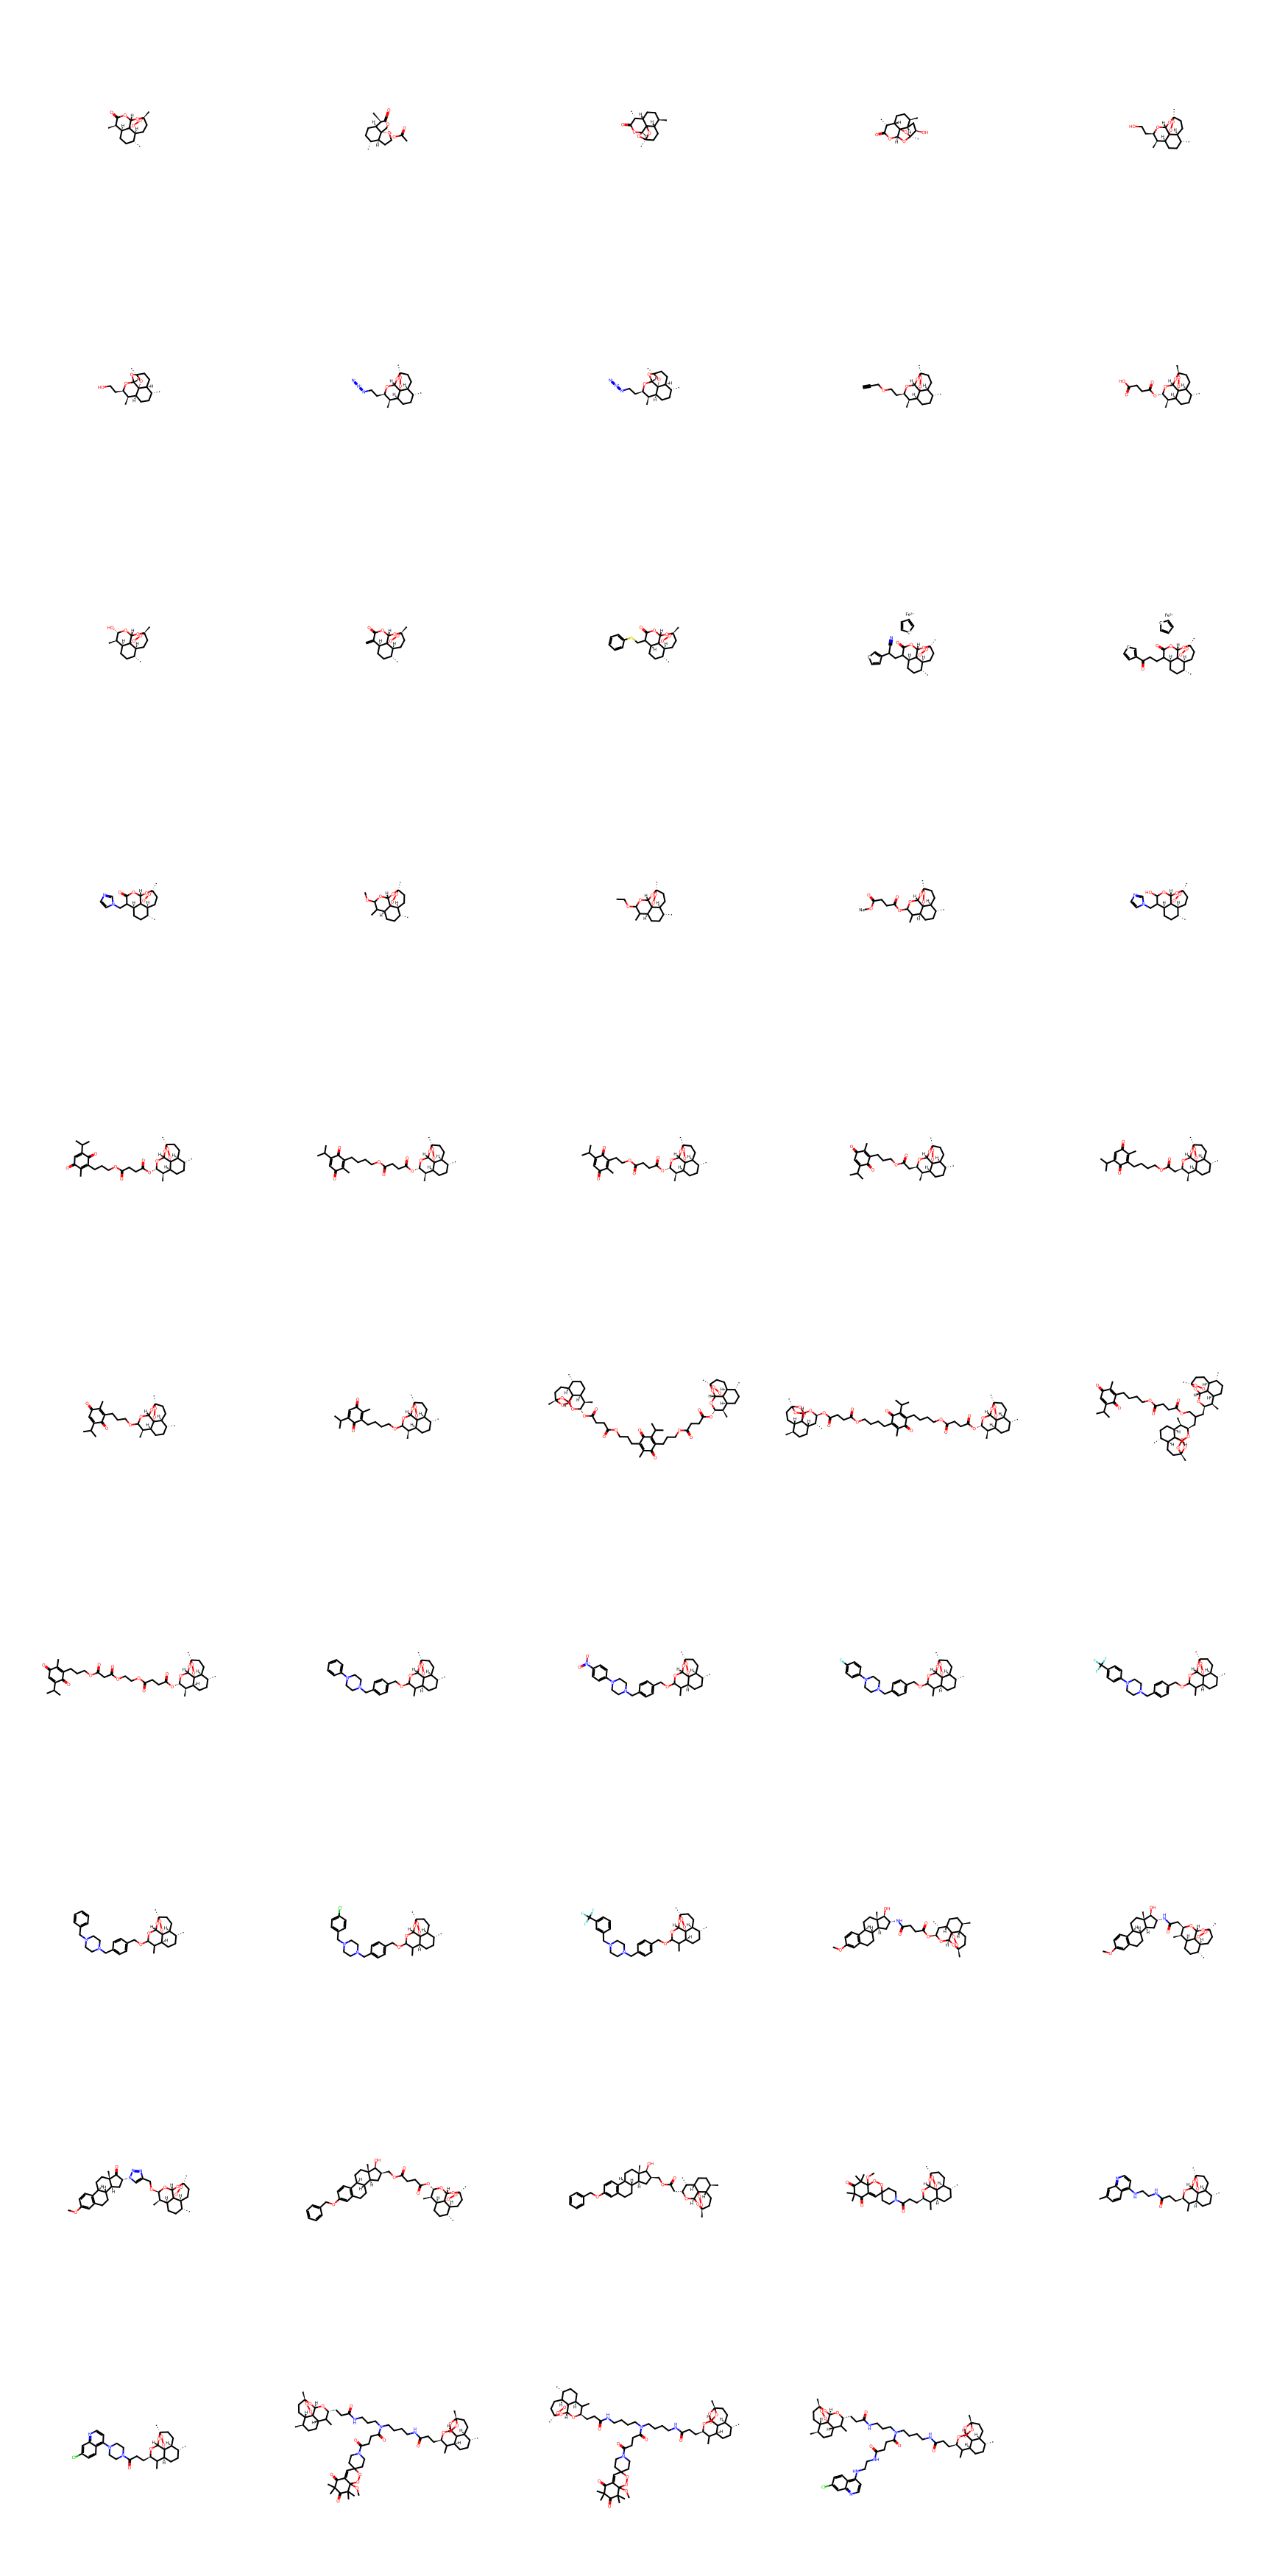

In [25]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import PandasTools, Draw
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Add a molecule column to the DataFrame
PandasTools.AddMoleculeColumnToFrame(data, smilesCol='SMILES')

# Select a valid range of molecules and their corresponding activities for display
# The data DataFrame has 132 rows, so indices like [345:409] are out of bounds.
# Displaying the first 10 molecules as an example.
grid_img = Draw.MolsToGridImage(data['ROMol'][0:49], molsPerRow=5, subImgSize=(350, 350),
                                #legends=[str(x) for x in data['Activity'][0:49].tolist()]
                                )
display(grid_img)

# CLUSTERING

### preparación



Aquí se organizan las moléculas en grupos (clústeres) basándose en su similitud estructural o química. Las moléculas dentro de un mismo clúster son muy similares entre sí, mientras que son diferentes a las moléculas de otros clústeres.

In [26]:
#PandasTools.AddMoleculeColumnToFrame(dataset,'SMILES', 'Structure')
PandasTools.AddMoleculeColumnToFrame(data,'SMILES', 'Structure')

/usr/local/lib/python3.13/dist-packages/rdkit/Chem/PandasTools.py:399: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  frame[molCol] = frame[smilesCol].map(Chem.MolFromSmiles)


In [27]:
# @title
import tqdm.notebook
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in data.Structure]
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [28]:
## Vamos a obtener la identificación del cluster 'cluster_id'
cluster_id = TaylorButina_Cluster(all_Mfpts, distThresh=0.6)
#_______________________________________________________________________
# Creamos un nuevo dataframe de nombre df_info, que tendrá el nombre del compuesto Cmpd, SMILES y el Cluster_number.
# En este nuevo dataframe agregaremos la información del cluster
df_info = data[['Cmpd','SMILES']].copy() # Seleccionamos algunas columnas desde data
df_info['Cluster_number'] = cluster_id #Colocamos la identificación del clúster en el dataframe.
print('La forma de df_info es: ')
print(df_info.shape)
'Se obtuvieron '+ str(len(set(cluster_id))) + ' clusters'

  0%|          | 0/131 [00:00<?, ?it/s]

La forma de df_info es: 
(132, 3)


'Se obtuvieron 35 clusters'

In [29]:
# @title
# Combine df_y y df_info
df_d = pd.concat([df_y, df_info], axis=1) # Pass the DataFrames as a list

df_d['cn_s'] = 'Cluster ' + df_d['Cluster_number'].astype(str)
# Crear una asignación de valores de Cluster_number a valores numéricos
cluster_mapping = {cluster: i + 1 for i, cluster in enumerate(sorted(df_d['Cluster_number'].unique()))}
# Crea la columna 'cn' en función del mapeo
df_d['cn'] = df_d['Cluster_number'].map(cluster_mapping)

fig = px.scatter(df_d, x="Cluster_number", y="Activity",
                 title="Compuestos ordenados por cluster",
                 width=800, height=550)

fig.update_layout(plot_bgcolor="white",  # Establecer color de fondo
                  paper_bgcolor="white")   # Establecer color de fondo del papel
fig.update_traces(marker=dict(line=dict(width=1, color='black'), color='blue')) #Configuración de marcador agregada con color estático
fig.update_traces(marker=dict(size=12)) # Aumentar el tamaño del marcador
fig.update_layout(hoverlabel_font_size=20)
app_marker = molplotly.add_molecules(fig=fig,df=df_d,
                                     smiles_col='SMILES',# title_col='Cmpd',
                                    #  color_col='cn_s', # Changed to a valid column for coloring
                                     caption_cols=['Cmpd'],
                                     fontsize=15, width=220)


/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



### gráfica

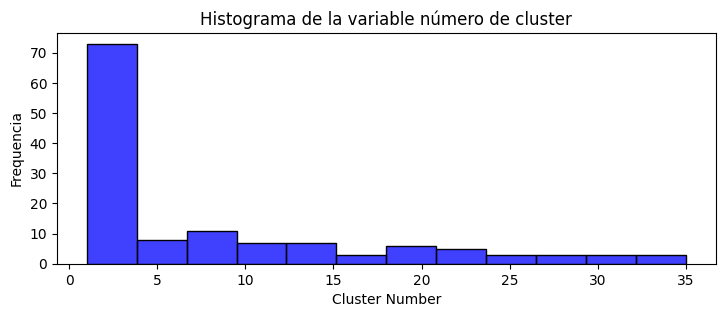

<IPython.core.display.Javascript object>

In [30]:
# Suponiendo que df_d ya está creado como en el código proporcionado
plt.figure(figsize=(8.5, 3))  # Ajuste el tamaño de la figura según sea necesario
sns.histplot(df_d['Cluster_number'], bins=12, color='b')  # kde=True agrega una estimación de densidad del kernel
plt.title('Histograma de la variable número de cluster')
plt.xlabel('Cluster Number')
plt.ylabel('Frequencia')

plt.show()
app_marker.run(port=8889)


# EXPLORACIÓN

Predicción de actividad de las nuevas moléculas

## Definimos al grupo xplor


Este grupo contiene dos conjuntos de moléculas, uno se obtiene a partir de diccionarios y otro a partir de un excel que se aloja en ggogle drive. Este último lo llamaremos mediante `! gdown -- id  ` y la funcion `pd.read_excel()`

___________________________
___________________________
___________________________
a) xplor

se puede definir a partir de diccionarios como smiles_dict que contiene las moléculas nuevas de las que queremos predecir su actividad biológica. En caso de usar el diccionario es necesario que la variable SMILES_LIST = True. La idea es que se use el diccionario para hacer predicciones rápidas de grupos pequeños de moléculas

Cada entrada es:

clave: nombre asignado a la molécula

valor: el SMILES, que es la representación lineal de su estructura química

Estos SMILES se usarán como grupo de exploración (xplor), es decir, como las moléculas que se evaluarán con el modelo QSAR para predecir actividad.


Para grandes grupos de moléculas se vuelve complicado usar un diccionario, y por lo regular sulen usarse archivos excel o csv, que contienen una columna con un identificador ('Cmpd') y el SMILE correspondiente. En este caso dicho archivo se importa desde drive con `!gdown --id `y se define el dataframe con pandas. para usar un archivo Excel o CSV es necesario que `excel = True`, y definir el ID del documento y su nombre con la función de `pd.read_excel()`


_____________________________
_____________________________
_____________________________

b) commercial_drugs

Este diccionario contiene moléculas comerciales conocidas. Compara resultados de predicción entre tus moléculas nuevas desconocidas y las comerciales conocidas, a traves de la representación del espacio quíico y el domino de aplicación.

Este grupo commercial_drugs NO entrena el modelo, sino que sirve para comparar moléculas conocidas o usadas comercialmente, en cuanto a predicciones y propiedades.

El modelo QSAR posteriormente usa el grupo xplor para:

- Leer sus SMILES

- Calcula sus descriptores moleculares

- Predice las propiedad de interés (actividad, logP, pIC50, etc) y dominio de aplicación

- Hace representación del espacio químico

In [31]:
excel = True
SMILES_LIST = False
comercial = False

In [32]:
smiles_dict = {'Manu021':'CN1C[C@H]2N(CC(C3=CC=C(OC)C=C3)=O)C[C@@H]1C2',
               'Manu022':'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@@H]4CN(C5N(C6=NC(C=CC(Br)=C7)=C7S6)C(CS5)=O)[C@@H](C4)C3)C=C21)=O',
               'Manu023' :'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@H]4CN(C5N(C6=NC(C=CC(Br)=C7)=C7S6)C(CS5)=O)[C@H](C4)C3)C=C21)=O',
               'Manu024': 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(Br)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               'Manu024': 'O=C(C1=CC(F)=C(N2[C@H]3CN(C4N(C5=NC(C=CC(Br)=C6)=C6S5)C(CS4)=O)[C@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               'Manu025' : 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(OCC)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               'Manu026' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=C(F)C=CC=C6)=N3',
               'Manu027' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=CC=C(F)C=C6)=N3',
               'Manu028' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=C(C(F)(F)F)C=CC=C6)=N3',
               'Manu029' : 'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@@H]4CN(C5N(C6=NC(C=CC(NC(C)=O)=C7)=C7S6)C(CS5)=O)[C@@H](C4)C3)C=C21)=O',
               'Manu030' : 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(OC)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               'ecp_01':'O=C1C2=C(C=C(F)C(N3CCN(C)CC3)=C2)C=NO1'}
comercial_drugs = {#______penicilinas________________________
               'penicilna G' : 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)CC3=CC=CC=C3)C(=O)O)C',
               'oxaciline': 'CC1=C(C(=NO1)C2=CC=CC=C2)C(=O)N[C@H]3[C@@H]4N(C3=O)[C@H](C(S4)(C)C)C(=O)O',
               'meticilina': 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)C3=C(C=CC=C3OC)OC)C(=O)O)C',
               'amoxicilin': 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)[C@@H](C3=CC=C(C=C3)O)N)C(=O)O)C',
               'minocyclin': 'CN(C)[C@H]1[C@@H]2C[C@@H]3CC4=C(C=CC(=C4C(=C3C(=O)[C@@]2(C(=C(C1=O)C(=O)N)O)O)O)O)N(C)C',
               'Ampicillin': 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)[C@@H](C3=CC=CC=C3)N)C(=O)O)C',
               'penicilin V': 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)COC3=CC=CC=C3)C(=O)O)C',
               'Dicloxacillin':'CC1=C(C(=NO1)C2=C(C=CC=C2Cl)Cl)C(=O)N[C@H]3[C@@H]4N(C3=O)[C@H](C(S4)(C)C)C(=O)O',
               'Piperacillin':'CCN1CCN(C(=O)C1=O)C(=O)N[C@H](C2=CC=CC=C2)C(=O)N[C@H]3[C@@H]4N(C3=O)[C@H](C(S4)(C)C)C(=O)O',
               #_______b-lactamasa inhibitors____________________________________
               'clavulanic acid': 'COC1=CC(=CC(=C1OC)OC)CC2=CN=C(N=C2N)N',
               'tazobactam': 'C[C@@]1([C@@H](N2[C@H](S1(=O)=O)CC2=O)C(=O)O)CN3C=CN=N3',
               'sulbactam': 'CC1([C@@H](N2[C@H](S1(=O)=O)CC2=O)C(=O)O)C',
               #______cephalospprins_____________________
               'cephalexin': 'CC1=C(N2[C@@H]([C@@H](C2=O)NC(=O)[C@@H](C3=CC=CC=C3)N)SC1)C(=O)O',
               'ceftriaxone':'CN1C(SCC2=C(C(O)=O)N3[C@H](SC2)[C@H](NC(/C(C4=CSC(N)=N4)=N\OC)=O)C3=O)=NC(C(N1)=O)=O',
               #_______inhibidores de pared___glucopeptidos____________________________
               'vancomicina': 'C[C@H]1[C@H]([C@@](C[C@@H](O1)O[C@@H]2[C@H]([C@@H]([C@H](O[C@H]2OC3=C4C=C5C=C3OC6=C(C=C(C=C6)[C@H]([C@H](C(=O)N[C@H](C(=O)N[C@H]5C(=O)N[C@@H]7C8=CC(=C(C=C8)O)C9=C(C=C(C=C9O)O)[C@H](NC(=O)[C@H]([C@@H](C1=CC(=C(O4)C=C1)Cl)O)NC7=O)C(=O)O)CC(=O)N)NC(=O)[C@@H](CC(C)C)NC)O)Cl)CO)O)O)(C)N)O',
               #____________lincosamidas
               'clindamicina': 'CCC[C@@H]1C[C@H](N(C1)C)C(=O)N[C@@H]([C@@H]2[C@@H]([C@@H]([C@H]([C@H](O2)SC)O)O)O)[C@H](C)Cl',
               #______tetraciclinas________________________
               'tetraciclina': 'C[C@@]1([C@H]2C[C@H]3[C@@H](C(=O)C(=C([C@]3(C(=O)C2=C(C4=C1C=CC=C4O)O)O)O)C(=O)N)N(C)C)O',
               #______sulfas_______________________
               'sulfamethoxazole':'CC1=CC(=NO1)NS(=O)(=O)C2=CC=C(C=C2)N',
               'sulfathiazole': 'C1=CC(=CC=C1N)S(=O)(=O)NC2=NC=CS2',
               #_______macrolides____________________________
               'azithromicyn': 'CC[C@@H]1[C@@]([C@@H]([C@H](N(C[C@@H](C[C@@]([C@@H]([C@H]([C@@H]([C@H](C(=O)O1)C)O[C@H]2C[C@@]([C@H]([C@@H](O2)C)O)(C)OC)C)O[C@H]3[C@@H]([C@H](C[C@H](O3)C)N(C)C)O)(C)O)C)C)C)O)(C)O',
               #inhibidor de la hidrofolato reductasa
               'trimethoprim': 'COC1=CC(=CC(=C1OC)OC)CC2=CN=C(N=C2N)N',
               #Fluoroquinolinas
               'levofloxacin': 'C[C@H]1COC2=C3N1C=C(C(=O)C3=CC(=C2N4CCN(CC4)C)F)C(=O)O',
               'ciprofloxacino' : 'C1CC1N2C=C(C(=O)C3=CC(=C(C=C32)N4CCNCC4)F)C(=O)O',
               'levofloxacin':'CN1C[C@@H]2C[C@H]1CN2C3=C(C=C4C(=C3)N(C=C(C4=O)C(=O)O)C5CC5)F'
               }


<>:29: SyntaxWarning:

invalid escape sequence '\O'

<>:29: SyntaxWarning:

invalid escape sequence '\O'

/tmp/ipykernel_635/1967575992.py:29: SyntaxWarning:

invalid escape sequence '\O'



In [33]:
xplor = pd.DataFrame()
if excel is True:
  #____DEBES DEFINIR ID Y NOMBRE DEL ARCHIVO EXCEL
  # El archivo EXCEL SOLO DEBE TENER DOS columnas: 'SMILES' y 'Cmpd'

  !gdown --id 1AQZgIy4uGwyHvrjeOJTxmumokoCaHEx-QNEo2S8jWN8 #IMPORTANTE
  excel = pd.read_excel("datEs.xlsx") #IMPORTANTE



  #________________________________________________
  #! gdown --id 1_vE6EPXJYAiPR1g6kBl2uE5u_-aJ1oft
  #xplor = pd.read_excel("drugs.xlsx")
  #______________________________________
  #______________________________________________

  excel['G'] = 'xplor'
  excel['Cluster_number'] = len(set(cluster_id))+1
  xplor = pd.concat([xplor, excel], ignore_index=True)
  print('Un archivo excel se adicionó a xplor')
else:
  print('NO se proceso EXCEL para adicionar a xplor')


if SMILES_LIST is True:
  #convierte smiles_dict en un dataframe
  sl = pd.DataFrame(list(smiles_dict.items()), columns=['Cmpd', 'SMILES'])
  sl['G'] = 'xplor'
  sl['Cluster_number'] = len(set(cluster_id))+1
  xplor = pd.concat([xplor, sl], ignore_index=True)
  print('Un diccionario con SMILES se adicionó a xplor')
else:
  print('NO se proceso el DICCIONARIO para adicionar a xplor')

if comercial is True:
  #convierte comercial_drugs en un dataframe
  com_drugs = pd.DataFrame(list(comercial_drugs.items()), columns=['Cmpd', 'SMILES'])
  com_drugs['G'] = 'comercial'
  com_drugs['Cluster_number'] = len(set(cluster_id))+2
  xplor = pd.concat([xplor, com_drugs], ignore_index=True)
  print('Los fármacos comerciales se tomaran en cuenta')
else:
  print('NO se tomaran en cuenta los fármacos comerciales')

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1AQZgIy4uGwyHvrjeOJTxmumokoCaHEx-QNEo2S8jWN8
From (redirected): https://docs.google.com/spreadsheets/d/1AQZgIy4uGwyHvrjeOJTxmumokoCaHEx-QNEo2S8jWN8/export?format=xlsx
To: /content/datEs.xlsx
5.78kB [00:00, 397kB/s]
Un archivo excel se adicionó a xplor
NO se proceso el DICCIONARIO para adicionar a xplor
NO se tomaran en cuenta los fármacos comerciales


In [34]:
filtered = xplor.copy()
#filtered = filtered[filtered['G'] == 'xplor']

In [35]:
from rdkit.Chem import PandasTools
PandasTools.AddMoleculeColumnToFrame(xplor,'SMILES', 'Structure')

,Cmpd,SMILES,G,Cluster_number,Structure
0,Olaf 1,O=C([C@H](C)C(CC[C@@H](C)[C@](CCO4)3[H])[C@@]3...,xplor,36,
1,Olaf 2,O=C1N(C(NC(N(C)C)=N)=N)C[C@]23C(CC[C@@H2][C@](...,xplor,36,
2,Olaf 3,O=C([C@H](C)C(CC[C@@H](C)[C@](CCO4)3[H])[C@@]3...,xplor,36,
3,Olaf 4,O=C1N(C(NC(N)=N)=N)C[C@]23C(CC[C@@H](C)[C@](CC...,xplor,36,
4,Olaf 5,O=C([C@H](C)C(CC[C@@H](C)[C@](CCO4)3[H])[C@@]3...,xplor,36,
5,Olaf 6,O=C1N(C(NC(NCCCC)=N)=N)C[C@]23C(CC[C@@H](C)[C@...,xplor,36,
6,Olaf 7,O=C([C@H](C)C(CC[C@@H](C)[C@](CCO4)3[H])[C@@]3...,xplor,36,
7,Olaf 8,O=C1N(C(NC(NCCC4=CC=CC=C4)=N)=N)C[C@]23C(CC[C@...,xplor,36,
8,Olaf 9,O=C([C@H](C)C(CC[C@@H](C)[C@](CCO4)3[H])[C@@]3...,xplor,36,
9,Olaf 10,O=C1N(C(NC/C=C(C)/C)=N)C[C@]23C(CC[C@@H](C)[C@...,xplor,36,

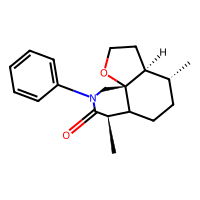
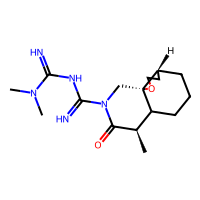
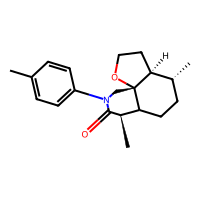
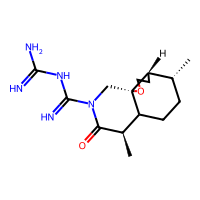
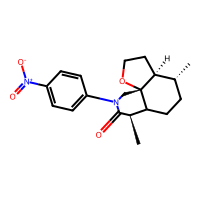
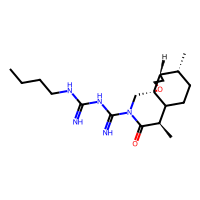
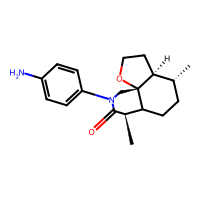
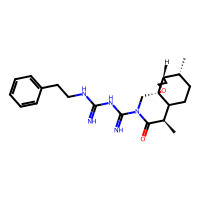
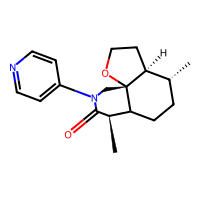
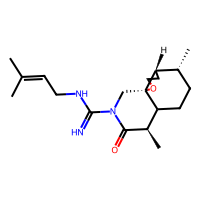

In [36]:
xplor

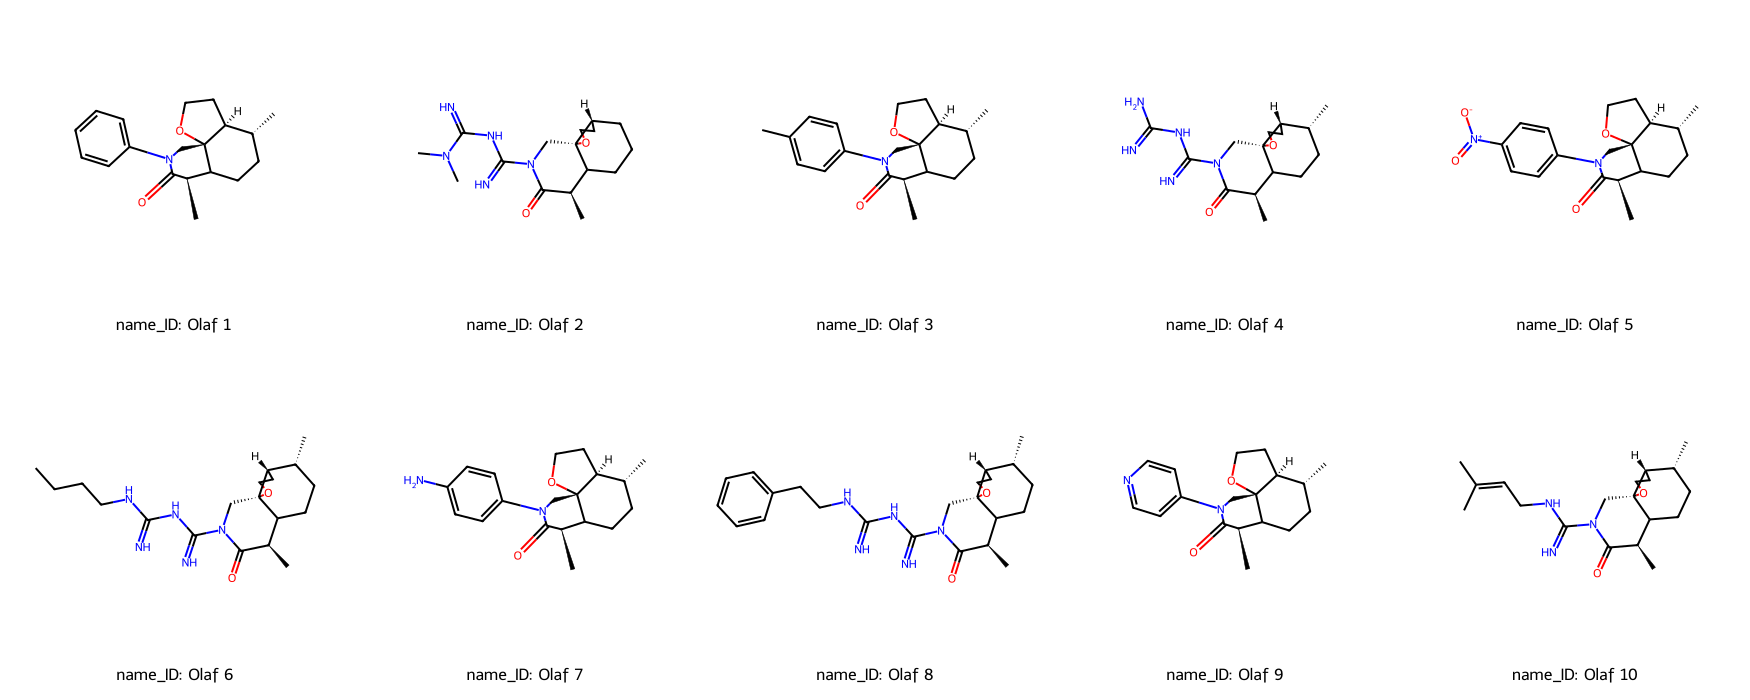

In [37]:
from rdkit.Chem import Draw
Draw.MolsToGridImage([x for x in xplor["Structure"]],#[20:56],
                     maxMols=100,
                     legends=['name_ID: ' + str(x) for x in xplor.Cmpd],
                     subImgSize=(350,350), molsPerRow=5)

# ESPACIO QUÍMICO



El espacio químico es un concepto fundamental en quimioinformática, es asociado con el conjunto de todas las moléculas posibles, que están descritas por un espacio multidimensional que representa propiedades estructurales, así como funcionales y su relación entre las moléculas molecular.

Se hace uso de dos tipos de representaciones

1.- Por PCA (Análisis de componentes principales)


2.- Por T-SNE,  (t-Distributed Stochastic Neighbor Embedding, por sus siglas en inglés) o Incrustación de vecinos estocásticos distribuidos en t.

Los descriptores que se representan en el espacio químico son

### Espacio químico descriptores

In [38]:
DATA_xplor = filtered.copy()
DATA_data = df_info.copy()
# prompt: combina DATA_data con df_y
DATA_data = pd.concat([DATA_data, df_y], axis=1)

In [39]:
# Generar descriptores
DATA_data["HBA"] = [Descriptors.NumHAcceptors(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
DATA_data["HBD"] = [Descriptors.NumHDonors(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
DATA_data["RB"] = [Descriptors.NumRotatableBonds(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
#DATA_data["RB"] = [Descriptors.MinPartialCharge(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
DATA_data["LogP"] = [Descriptors.MolLogP(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
DATA_data["TPSA"] = [Descriptors.TPSA(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]
DATA_data["MW"] = [Descriptors.MolWt(y) for y in (Chem.MolFromSmiles(x) for x in DATA_data["SMILES"])]

In [40]:
# Generar descriptores
DATA_xplor["HBA"] = [Descriptors.NumHAcceptors(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["HBD"] = [Descriptors.NumHDonors(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["RB"] = [Descriptors.NumRotatableBonds(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
#DATA_xplor["RB"] = [Descriptors.MinPartialCharge(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["LogP"] = [Descriptors.MolLogP(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["TPSA"] = [Descriptors.TPSA(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["MW"] = [Descriptors.MolWt(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]

In [41]:
DATA_data

,Cmpd,SMILES,Cluster_number,Activity,HBA,HBD,RB,LogP,TPSA,MW
0,Artemisinina,[H][C@@]12CC[C@@H](C)[C@]3([H])CC[C@]4(C)OO[C@...,1,7.982967,5,0,0,2.39490,53.99,282.336
1,Artemisinina G,[H][C@@]12CCO[C@]11[C@@]([H])(OC(C)=O)OC(=O)[C...,16,7.031657,5,0,1,1.88990,61.83,282.336
2,deoxyartemisinin,[H][C@]12O[C@]3(C)CC[C@@]4([H])[C@H](C)CC[C@@]...,3,3.840162,4,0,0,2.46330,44.76,266.337
3,4α-hydroxydeoxyartemisinin,[H][C@@]12O[C@@]3(C)O[C@]11[C@@]([H])(CC[C@@H]...,15,4.625068,5,1,0,1.43410,64.99,282.336
4,6a,C[C@H]1[C@@H](CCO)O[C@H]2[C@@]34[C@](CC[C@@](C...,1,7.950000,5,1,2,2.61930,57.15,312.406
...,...,...,...,...,...,...,...,...,...,...
182,258,ClC1=CC=C2C(N=CC=C2NCCCN3CC(COC4=CC=C(/C=N/NC(...,8,6.585027,10,2,11,4.37450,129.35,544.019
183,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,17,6.302361,7,2,7,4.05430,114.27,535.967
184,262,ClC(C=C1)=CC2=C1C(NCC3=CN(CC(N4C)=C(C(OC)=O)C(...,17,6.860027,7,2,7,4.05430,114.27,535.967
185,337,CC1=C2C(N=C(OC)C(CNCC3=CC=CC=N3)=C2)=CC(C)=C1,24,6.638272,4,1,5,3.54504,47.04,307.397


In [42]:
chemspace_data = DATA_data.copy()


In [43]:
# chemspace_data = DATA_data.copy()
#A chemspace_data agrega una columna llada G , que tenga el valor 'data' para todos los elementos
chemspace_data['G'] = 'data'
# Fusionar chemspace_data con DA_data según la columna 'Cmpd'
chemspace_data = pd.merge(chemspace_data, DATA_data[['Cmpd']], on='Cmpd', how='left')
# Now chemspace_data contains the 'LeverageMethod_domain' column from DA_data.
#chemspace_data

In [44]:
chemspace_xplor = DATA_xplor.copy()
# prompt: en chemspace_xplor elimina las columnas: ZIN_ID, G, Component1, Component2, Component3
chemspace_xplor = chemspace_xplor.drop(columns=['ZINC_ID', 'component1', 'component2', 'component3'], errors='ignore')
# prompt: en chemspace_xplor cambia el nombre de la columna 'pred' por 'Activity'
chemspace_xplor = chemspace_xplor.rename(columns={'pred': 'Activity'})
# prompt: agrega la columna G a chemspace_xplor

#chemspace_xplor['G'] = 'comb'
#chemspace_xplor['Cluster_number'] = int(len(set(cluster_id))+1)

In [45]:
# Concatenar a lo largo de filas (eje=0)
chemspace = pd.concat([chemspace_data, chemspace_xplor], axis=0, ignore_index=True)

# Si es necesario, puede restablecer el índice:
# chemspace = chemspace.reset_index()

# A chemspace, agrega, una columna que se llame G2, que tenga valores numéricos para cada valor de G, esto servira mása adelante para visualizar datos en molplotly
# Crear un mapeo de valores 'G' a valores numéricos
g_mapping = {'data': 1, 'xplor': 2, 'comb': 3}  # Example mapping
# Cree la columna 'G2' en función del mapeo
chemspace['G2'] = chemspace['G'].map(g_mapping)
# Añadimos una columna que nos permitirá visualizar la información de los clusters con plotly

chemspace['cn_s'] = 'Cluster ' + chemspace['Cluster_number'].astype(str)
# Crear una asignación de valores de Cluster_number a valores numéricos
cluster_mapping = {cluster: i + 1 for i, cluster in enumerate(sorted(chemspace['Cluster_number'].unique()))}
# Crea la columna 'cn' en función del mapeo
chemspace['cn'] = chemspace['Cluster_number'].map(cluster_mapping)

In [46]:
chemspace

,Cmpd,SMILES,Cluster_number,Activity,HBA,HBD,RB,LogP,TPSA,MW,G,G2,cn_s,cn
0,Artemisinina,[H][C@@]12CC[C@@H](C)[C@]3([H])CC[C@]4(C)OO[C@...,1,7.982967,5,0,0,2.39490,53.99,282.336,data,1,Cluster 1,1
1,Artemisinina G,[H][C@@]12CCO[C@]11[C@@]([H])(OC(C)=O)OC(=O)[C...,16,7.031657,5,0,1,1.88990,61.83,282.336,data,1,Cluster 16,16
2,deoxyartemisinin,[H][C@]12O[C@]3(C)CC[C@@]4([H])[C@H](C)CC[C@@]...,3,3.840162,4,0,0,2.46330,44.76,266.337,data,1,Cluster 3,3
3,4α-hydroxydeoxyartemisinin,[H][C@@]12O[C@@]3(C)O[C@]11[C@@]([H])(CC[C@@H]...,15,4.625068,5,1,0,1.43410,64.99,282.336,data,1,Cluster 15,15
4,6a,C[C@H]1[C@@H](CCO)O[C@H]2[C@@]34[C@](CC[C@@](C...,1,7.950000,5,1,2,2.61930,57.15,312.406,data,1,Cluster 1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
277,Olaf 6,O=C1N(C(NC(NCCCC)=N)=N)C[C@]23C(CC[C@@H](C)[C@...,36,NaN,4,4,3,2.13494,101.30,363.506,xplor,2,Cluster 36,36
278,Olaf 7,O=C([C@H](C)C(CC[C@@H](C)[C@](CCO4)3[H])[C@@]3...,36,NaN,3,1,1,3.07290,55.56,314.429,xplor,2,Cluster 36,36
279,Olaf 8,O=C1N(C(NC(NCCC4=CC=CC=C4)=N)=N)C[C@]23C(CC[C@...,36,NaN,4,4,3,2.57754,101.30,411.550,xplor,2,Cluster 36,36
280,Olaf 9,O=C([C@H](C)C(CC[C@@H](C)[C@](CCO4)3[H])[C@@]3...,36,NaN,3,0,1,2.88570,42.43,300.402,xplor,2,Cluster 36,36


### Representación de propiedades

In [47]:
# @title
# prompt: has una matriz de dispersión con plotly, con el df chemspace

import plotly.express as px
#________________Por si se enciman los datos_________________________________
a = chemspace.copy()
#a = chemspace[chemspace['cn'].isin([2,3,4,5,6,7,8,9,10,11,12,13])]
#a = chemspace[chemspace['G2'].isin([0,1,3])]
#________________Definimos la gráfica______________________________
fig1 = px.scatter_matrix(data_frame=a,
                         #data_frame=a, #Por si se enciman los datos
                         #_________________________________
                         dimensions=["HBA", "HBD", "RB", "LogP", "TPSA", "MW", 'Activity'
                                     ],
                         #_______color_________________________________________
                         color="G",#color="cn_s",
                        #  color_discrete_map={'data': 'blue', 'xplor': 'red', 'comercial': 'green'}, # <-- Add this line to define colors for G2 values
                         #color_discrete_sequence=px.colors.qualitative.Dark24,
                         #____________Color___________________________________
                         title='Matriz de dispersión del Espacio Químico, Descriptores Individuales ',
                         height=1000,width=1500)
#________________Formato________________________________________________________
# fig1.update_layout(plot_bgcolor="white", paper_bgcolor="white")  # Set plot background color
fig1.update_traces(diagonal_visible=False, #marker=dict(line=dict(width=1, color='black'))
) #Added marker settings
#_______________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig1,
                                     #_________________________________________
                                     df=a,
                                     #df=a,
                                     #_________________________________________
                                     smiles_col='SMILES',
                                     #____color_______________________________
                                     color_col='G', #color="cn_s",
                                     caption_cols=['Cmpd', 'G', 'cn_s',"HBA", "HBD", "RB", "LogP", "TPSA", "MW", 'Activity'],
                                     show_coords=False,
                                     #________________________________________
                                     fontsize=20, width=350)
app_marker.run(port=8960)
#fig.show()

/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

In [48]:
chemspace

,Cmpd,SMILES,Cluster_number,Activity,HBA,HBD,RB,LogP,TPSA,MW,G,G2,cn_s,cn
0,Artemisinina,[H][C@@]12CC[C@@H](C)[C@]3([H])CC[C@]4(C)OO[C@...,1,7.982967,5,0,0,2.39490,53.99,282.336,data,1,Cluster 1,1
1,Artemisinina G,[H][C@@]12CCO[C@]11[C@@]([H])(OC(C)=O)OC(=O)[C...,16,7.031657,5,0,1,1.88990,61.83,282.336,data,1,Cluster 16,16
2,deoxyartemisinin,[H][C@]12O[C@]3(C)CC[C@@]4([H])[C@H](C)CC[C@@]...,3,3.840162,4,0,0,2.46330,44.76,266.337,data,1,Cluster 3,3
3,4α-hydroxydeoxyartemisinin,[H][C@@]12O[C@@]3(C)O[C@]11[C@@]([H])(CC[C@@H]...,15,4.625068,5,1,0,1.43410,64.99,282.336,data,1,Cluster 15,15
4,6a,C[C@H]1[C@@H](CCO)O[C@H]2[C@@]34[C@](CC[C@@](C...,1,7.950000,5,1,2,2.61930,57.15,312.406,data,1,Cluster 1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
277,Olaf 6,O=C1N(C(NC(NCCCC)=N)=N)C[C@]23C(CC[C@@H](C)[C@...,36,NaN,4,4,3,2.13494,101.30,363.506,xplor,2,Cluster 36,36
278,Olaf 7,O=C([C@H](C)C(CC[C@@H](C)[C@](CCO4)3[H])[C@@]3...,36,NaN,3,1,1,3.07290,55.56,314.429,xplor,2,Cluster 36,36
279,Olaf 8,O=C1N(C(NC(NCCC4=CC=CC=C4)=N)=N)C[C@]23C(CC[C@...,36,NaN,4,4,3,2.57754,101.30,411.550,xplor,2,Cluster 36,36
280,Olaf 9,O=C([C@H](C)C(CC[C@@H](C)[C@](CCO4)3[H])[C@@]3...,36,NaN,3,0,1,2.88570,42.43,300.402,xplor,2,Cluster 36,36


In [49]:
# import plotly.express as px
# import molplotly

# # Creamos una gráfica donde se puden ver las propiedades individuales de las moléculas a evaluar comparadas con
# # lás moléculas de los datos iniciales

# #________________Por si se enciman los datos_________________________________
# a = chemspace.copy()
# #a = chemspace[chemspace['cn'].isin([2,3,4,5,6,7,8,9,10,11,12,13])]
# #a = chemspace[chemspace['G2'].isin([0,1,3])]
# #________________Definimos la gráfica______________________________

# fig = px.scatter(data_frame=a, x="LogP", y="Activity",
#                  title="Características individuales",
#                  size='Activity', # Set bubble size based on Activity


#                  #_______Color_________________________
#                  color = 'cn_s',
#                  height= 700, width= 1500,



#                  )
# #________________Formato________________________________________________________
# fig.update_layout(plot_bgcolor="white", paper_bgcolor="white") # Set background color
# fig.update_traces(marker=dict(line=dict(width=1, color='black')))
# fig.update_traces(marker=dict(size=12)) # Base size, will be scaled by 'Activity'
# ##_________________________________________________________________________
# app_marker = molplotly.add_molecules(fig=fig,
#                                      df=a,
#                                      smiles_col='SMILES',
#                                      color_col = 'cn_s',
#                                      caption_cols=['Cmpd', 'Activity', 'G'],
#                                      fontsize=20, width=350)
# app_marker.run(port=8961)

In [50]:
# Creamos una gráfica de dispersión en 3D donde se puden ver las propiedades individuales de las moléculas a evaluar comparadas con
# lás moléculas de los datos iniciales

#________________Por si se enciman los datos_________________________________
a = chemspace.copy()
#a = chemspace[chemspace['cn'].isin([2,3,4,5,6,7,8,9,10,11,12,13])]
#a = chemspace[chemspace['G2'].isin([0,1,3])]
#___________________________________________________________________________
#________________Definimos la gráfica______________________________
fig = px.scatter_3d(data_frame=a, x="MW", y="LogP", z="Activity",
                    title="Características individuales",
                    #_____color________
                    color='G',
                    #color = 'cn'
                    )
#________________Formato________________________________________________________
fig.update_layout(plot_bgcolor="white", paper_bgcolor="white") # Set background color
#_______________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig,
                                     df=a,
                                     smiles_col='SMILES',
                                     color_col='G',
                                     fontsize=15,
                                     show_coords=False,
                                     caption_cols=['Cmpd','Activity', 'G'],
                                     width=210)
app_marker.run(port=8707)

/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

# Representación del Espacio Químico por PCA





## Preparación

Se usa para reducir la dimensionalidad, asignando pesos a los descriptores, y generando los nuevos Componentents Principales. Esto nos permite visualizar la represeantación del espacio Químico en dos o tres dimensiones.

Las moléculas que comparten propiedades se acercan entre si, y entre más distintas sean entre ellas, mayor será la distancia euclidiana entre los puntos.

In [51]:
data_k=chemspace.copy()
#Dividir matriz
data_k = data_k.iloc[:,4:10].values # Seleccionar columnas con descriptores
data_k = pd.DataFrame(data_k)
#data

In [52]:
# Normalizar datos
from sklearn.preprocessing import StandardScaler
data_std = StandardScaler().fit_transform(data_k)

In [53]:
# pca.fit
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
pca_results = pca.fit_transform(data_std)
#pca_results

In [54]:
# Seleccionar información complementaria
label = chemspace[["Cmpd", "SMILES", "Activity", 'G', 'Cluster_number']]
label = label.to_numpy()

In [55]:
# Concatenar matrices de numpy
arr = np.concatenate((label, pca_results), axis = 1)
# Crear un nuevo dataframe
pca_dataset = pd.DataFrame(data=arr, columns = ['Cmpd',"SMILES", "Activity",'G','Cluster_number','component1', 'component2', 'component3'])
#pca_dataset.head(2)

In [56]:
#Las cargas (loadings) representan los pesos o coeficientes de los PC's
loadings = []
#Inicia un bucle que itera sobre cada componente principal.
# pca.n_components se refiere al número de componentes principales calculados durante el análisis PCA.
# # pca.components_ es un atributo del objeto PCA ajustado (fit) que almacena las cargas (loadings) de todos los componentes principales.
for i in range(pca.n_components):
  loadings.append(pca.components_[i])
#pca loadings es una datafrme que relaciona los descripotres con los pesos de los PCA´s
pca_loadings = pd.DataFrame(data=loadings, columns=data_k.columns)
# Renombramos las columnas
pca_loadings = pca_loadings.rename(columns={0: "HBA", 1: "HBD", 2: "RB", 3: "LogP", 4: "TPSA", 5: "MW"})
# A pca_loadings vuelve cambia el indice qu ecomience desde uno
pca_loadings.index = range(1, len(pca_loadings) + 1)

In [57]:
# Obtenemos las ecuaciones de PC's
equations = {}
for index, row in pca_loadings.iterrows():
  equation = "PC{} = ".format(index)
  for col, value in row.items():
    equation += "{:.4f}*{} + ".format(value, col)
  equations["PC{}".format(index)] = equation[:-3]  # Remove the last " + "
for pc, equation in equations.items():
  print(equation)

PC1 = 0.4614*HBA + 0.1154*HBD + 0.4521*RB + 0.3660*LogP + 0.4551*TPSA + 0.4778*MW
PC2 = -0.1207*HBA + 0.8758*HBD + 0.1130*RB + -0.3892*LogP + 0.2090*TPSA + -0.1028*MW
PC3 = -0.3909*HBA + 0.3788*HBD + -0.0418*RB + 0.7651*LogP + -0.3363*TPSA + 0.0599*MW


###  PCA representación de pesos



Muestra la relación de los descriptres con respecto a los primeros 3 componentes principales.

In [58]:
# @title
# Crea una figura
figx = go.Figure()
# Itera sobre cada índice (PC) y agrega trazas (inforación de cada PC) al gráfico de barras
for index in pca_loadings.index:
  figx.add_trace(go.Bar(x=pca_loadings.columns, # Nombres de los descriptores
                        y=pca_loadings.loc[index],  # Valores para cada uno de los PC's
                        name=index))  # Nombre de la traza (PC)
#____________Formateo_______________
figx.update_layout(title="Contribución de los Descriptores a cada PC para el Espacio Químico",
                   xaxis_title="Descriptores",
                   yaxis_title="Weight",
                   plot_bgcolor='white',
                   paper_bgcolor='white',
                   barmode='group')  # Agrupa las barras por descriptor
figx.show()# Muestra la figura

### PCA varianza acumulada

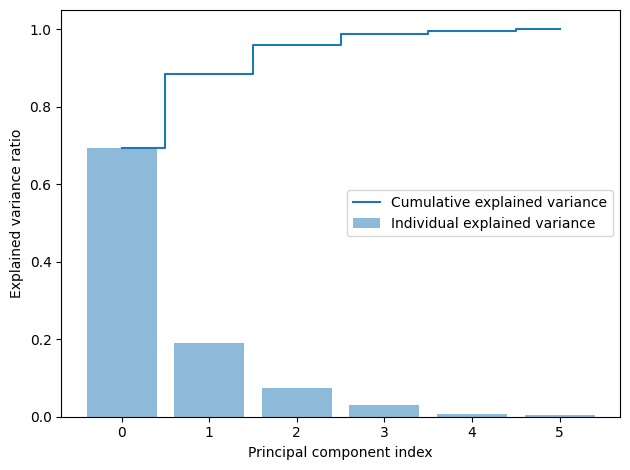

In [59]:
# @title
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(data_k)
X_train_std = sc.transform(data_k)

pca = PCA()

# Determine transformed features
X_train_pca = pca.fit_transform(X_train_std)

# Determine explained variance using explained_variance_ration_ attribute
exp_var_pca = pca.explained_variance_ratio_
#
# Cumulative sum of eigenvalues; This will be used to create step plot
# for visualizing the variance explained by each principal component.
cum_sum_eigenvalues = np.cumsum(exp_var_pca)
#
# Create the visualization plot
import matplotlib.pyplot as plt
plt.bar(range(0,len(exp_var_pca)), exp_var_pca, alpha=0.5, align='center', label='Individual explained variance')
plt.step(range(0,len(cum_sum_eigenvalues)), cum_sum_eigenvalues, where='mid',label='Cumulative explained variance')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

In [60]:
# # Agregue la columna 'Levarage_domain' a pca_dataset
# da = chemspace['LeverageMethod_domain']  # Using chemspace DataFrame to access the column
# # Restablecer el índice de pca_dataset para que coincida con chemspace
# pca_dataset = pca_dataset.reset_index(drop=True)
# # Agregar la nueva columna a pca_dataset
# pca_dataset['LeverageMethod_domain'] = da

## Representación del espacio químico por PCA



### Preparación

In [61]:
# Crea una columna en pca_dataset que se llamará cn, tendra valores numéricos uno para cada tipo de valor de Cluster_number
# Crear una asignación de valores de Cluster_number a valores numéricos
cluster_mapping = {cluster: i + 1 for i, cluster in enumerate(sorted(pca_dataset['Cluster_number'].unique()))}
# Crea la columna 'cn' en función del mapeo
pca_dataset['cn'] = pca_dataset['Cluster_number'].map(cluster_mapping)
# Crea una columna en pca_datset, se llamará cn_s, tendra valores en cadenas dirán cluster + n, donde es el número de cluster
pca_dataset['cn_s'] = 'cluster ' + pca_dataset['cn'].astype(str)
# Cree la columna 'G2' en función de la asignación
pca_dataset['fraction1'] = pca_dataset['G'].map(g_mapping)

In [62]:
# @title
#Graficar gráfica de dispersión Activity vs PC1

#________________Por si se enciman los datos_________________________________
a = pca_dataset.copy()
# a = pca_dataset[pca_dataset['G'] != 'xplor'].copy()
#a = pca_dataset[pca_dataset['fraction1'].isin([])]# Filter out 'xplor' group
#a = pca_dataset[pca_dataset['cn'].isin([1,2,3,4,5,6,.7,8,9,10,11,12,13])]
#________________Definimos la gráfica_______________________________________

dato1='component1'
dato3='Component3'
#________________
dato2='component2'
#___________________________________________________________________________
fig_pca = px.scatter(data_frame=a, #Por si se enciman los datos
                     #____coordenadas______________--
                     x=dato1,y=dato2,
                     #_____Color_____________-color='cn',
                     color='G',
                     color_discrete_map={'data': 'blue', 'comercial': 'red'}, # Invierte colores
                     #______________________
                     title=f'{dato2} vs {dato1}',
                     width=800,height=600)
#______________formateo_______________________________________________________
fig_pca.update_layout(plot_bgcolor="white", paper_bgcolor="white") # Elige color del fondo
fig_pca.update_traces(marker=dict(line=dict(width=1, color='black'))) # Configuración de marcador agregada
fig_pca.update_traces(marker=dict(size=12)) # Aumentar el tamaño del marcador
#______________________________________________________________________________

# Añadir anotaciones SÓLO para puntos 'comerciales'
for index, row in a.iterrows():
    if row['G'] == 'comercial': # Solo agregue etiquetas para el grupo 'comercial'
        fig_pca.add_annotation(
            x=row[dato1],
            y=row[dato2],
            text=row['Cmpd'],
            showarrow=False,
            yshift=10,  # Desplazar el texto ligeramente por encima del punto
            font=dict(
                size=14,
                color="black"
            )
        )

app_marker2dpca = molplotly.add_molecules(fig=fig_pca,
                                     #_____________dataframe___________________
                                     df=a,
                                     #__________________________________________
                                     smiles_col='SMILES',
#                                    title_col='Cmpd',
                                     #_____________color_________________________
                                     color_col='G',
                                     #color_col='cn',
                                     #_________________________________________
                                    fontsize=20, width=220,
                                     caption_cols=[#dato3,
                                                   #'Cmpd'
                                                   ],
                                     show_coords=False)


/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



In [63]:
# @title
#Grafica de dispersión en 3D Activity vs PC1 vs PC2
#________________Por si se enciman los datos_________________________________

a = pca_dataset.copy()
#a = pca_dataset[pca_dataset['fraction1'].isin([])]
#a = pca_dataset[pca_dataset['cn'].isin([6,9,#10,11,12,13])]

#________________Definimos la gráfica_______________________________________
dato1='component1'
#dato2='Activity'
dato2='component3'
dato3='component2'
#_________
dato4='Activity'
#dato4='component3'
#__________________________________________________________________________
fig_pca = px.scatter_3d(data_frame=a,
                        #data_frame=a, #Por si se enciman los datos
                        #______coordenadas__________________________________
                        x=dato3,
                        y=dato1,
                        z=dato2,
                        #______color________________________________________
                        color='G',
                        #color='cn',
                        #___________________________________________________
                        title=f'{dato2} vs {dato1} vs {dato3}',
                        width=900, height=900)
#______________formateo_______________________________________________________
fig_pca.update_layout(plot_bgcolor="white", paper_bgcolor="white") #Set background color
fig_pca.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_pca.update_traces(marker=dict(size=5)) # Increase marker size
#______________________________________________________________________________
app_marker3dpca = molplotly.add_molecules(fig=fig_pca,
                                     #___________dataframe__________________
                                     df=a,
                                     #df=a,
                                     #______________________________________
                                     smiles_col='SMILES',
                                   #  title_col='cn_s',
                                     #____________color_____________________
                                     #color_col='cn',
                                     color_col='G',
                                     #________________________________________
                                     show_coords=False,
                                     caption_cols=['Cmpd','G'],
                                     fontsize=15, width=210)


/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



## Gráficas

In [64]:
figx.update_layout(width=800, height=250)
figx.show()
app_marker2dpca.run(port=8708)
app_marker3dpca.run(port=8709)



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Representación del Espacio Químico por T-SNE

## Preparación



La principal aplicación de la técnica t-SNE es la transformación no lineal de los datos, lo que nos permite visualizar la representación de nuestros datos en un espacio de dos o tres dimensiones, dado que las transformaciones son no lineales, esto evita que se acumulen los puntos en el centro (a diferencia de la técnica de PCA) tratando de preservar la estructura de vecindad.

In [65]:
# @title
## Entrenar modelo t-SNE
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
data_tsne = chemspace.copy()
data_tsne = data_tsne.drop(labels = ["Cmpd", "Cluster_number","SMILES",'Activity','G',	'G2',	'cn_s',	'cn'],axis = 1)
data_tsne = StandardScaler().fit_transform(data_tsne)
tsne = TSNE(n_components=3, verbose=1, perplexity=3, max_iter=10000, early_exaggeration=5)
tsne_results = tsne.fit_transform(data_tsne)
#tsne_results
# Seleccionar impormación complementaria
label = chemspace[["Cmpd", "Cluster_number","SMILES",'Activity','G',	'G2',	'cn_s',	'cn']]
label = label.to_numpy()

# Concatenar matrices de numpy
arr = np.concatenate((label, tsne_results), axis = 1)

# Crear un nuevo dataframe
tsne_dataset = pd.DataFrame(data=arr,
                            columns = ["Cmpd", "Cluster_number","SMILES",'Activity','G','G2', 'cn_s',	'cn','axis1', 'axis2','axis3'])
#tsne_dataset

# prompt: ordena tsne_dataset por orden ascendente en cn_s

tsne_dataset = tsne_dataset.sort_values(by=['cn_s'])
#tsne_dataset

# prompt: en tsne_dataset elimina los lementos repetidos

# Eliminar filas duplicadas en tsne_dataset basándose en la columna 'SMILES'
tsne_dataset = tsne_dataset.drop_duplicates(subset='SMILES')
#tsne_dataset

[t-SNE] Computing 10 nearest neighbors...
[t-SNE] Indexed 282 samples in 0.003s...
[t-SNE] Computed neighbors for 282 samples in 0.003s...
[t-SNE] Computed conditional probabilities for sample 282 / 282
[t-SNE] Mean sigma: 0.000000
[t-SNE] KL divergence after 250 iterations with early exaggeration: 9.355271
[t-SNE] KL divergence after 10000 iterations: -5.709731


In [66]:
import plotly.express as px
import molplotly

# Filter out 'xplor' group from tsne_dataset
tsne_dataset_filtered = tsne_dataset.copy()
# tsne_dataset_filtered = tsne_dataset[tsne_dataset['G'] != 'xplor']

fig_tsne2d = px.scatter(tsne_dataset_filtered,
                      x='axis1', y='axis2',
                      #color='cn',
                      color='G',
                        title='t-SNE',
                      #color_discrete_sequece=px.colors.qualitative.Plotly,
                      width=900,height=700)

# Set background color to white
fig_tsne2d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne2d.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne2d.update_traces(marker=dict(size=12)) # Increase marker size
# También puedes usar una sintaxis más directa (atajo):
fig_tsne2d.update_layout(hoverlabel_font_size=20)

#fig_tsne.update_layout(showlegend=False) # Esta línea elimina la leyenda.
#fig_tsne.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="center", x=-10.0))
app_marker2d = molplotly.add_molecules(fig=fig_tsne2d,
                                       df=tsne_dataset_filtered,
                                       smiles_col='SMILES',
                                       #title_col='Cmpd',
                                       #color_col='cn',
                                       color_col='G',
                                       width=350, fontsize= 25,
                                       caption_cols=['cn_s','Activity'],
                                          show_coords=False
                                       )
#_________________________________________________________________________________________________________


fig_tsne3d = px.scatter_3d(tsne_dataset_filtered,
                      x='axis1', y='axis3', z='axis2',
                      color='G', #Otra opción de color
                      #color='cn', #Otra opción de color
                      title='t-SNE',
                      hover_data={'cn_s':True,'Activity':True, 'axis1': False, 'axis2': False, 'axis3':False},
                      hover_name='Cmpd',
                      width=900,height=700)

# Establecer el color de fondo en blanco
fig_tsne3d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne3d.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne3d.update_traces(marker=dict(size=8)) # Increase marker size
# También puedes usar una sintaxis más directa (atajo):
fig_tsne3d.update_layout(hoverlabel_font_size=20)

app_marker3d = molplotly.add_molecules(fig=fig_tsne3d,
                                       df=tsne_dataset_filtered,
                                       smiles_col='SMILES',
                                       color_col='G',
                                       width=350, fontsize= 25,
                                       caption_cols=['Cmpd', 'cn_s','Activity'],
                                       show_coords=False
                                      )

#fig_tsne.update_layout(showlegend=False) # Esta línea elimina la leyenda.
#fig_tsne.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="center", x=-10.0))
#                                       )
#_____________________________________________________________________________________________________


/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.

/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



## Gráficas tSNE

In [67]:
app_marker2d.run(port=8710)
app_marker3d.run(port=8711)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# UMAP



In [68]:
# Select the descriptor columns from chemspace for UMAP
descriptor_cols = ['HBA', 'HBD', 'RB', 'LogP', 'TPSA', 'MW']
X_descriptors = chemspace[descriptor_cols].copy()

# Handle potential NaN values by imputing with the mean (similar to previous steps for other models)
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X_descriptors)

# Apply StandardScaler to the descriptors
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Apply UMAP dimensionality reduction (using 3 components for more detail, can be changed to 2)
reducer = umap.UMAP(n_components=3, random_state=RANDOM_STATE, n_neighbors=20, learning_rate=0.5)
#reducer = umap.UMAP(n_components=2, random_state=RANDOM_STATE, n_neighbors=15
umap_results = reducer.fit_transform(X_scaled)

# Create a DataFrame for UMAP results
umap_df = pd.DataFrame(umap_results, columns=['UMAP1', 'UMAP2', 'UMAP3'])

# Add relevant original columns to the UMAP DataFrame
umap_df['Cmpd'] = chemspace['Cmpd'].values
umap_df['SMILES'] = chemspace['SMILES'].values
umap_df['Activity'] = chemspace['Activity'].values
umap_df['Cluster_number'] = chemspace['Cluster_number'].values
umap_df['G'] = chemspace['G'].values



/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



In [69]:
import plotly.express as px
import warnings

warnings.filterwarnings("ignore", message="JupyterDash is deprecated, use Dash instead.")

# Prepare data for plotting, ensuring 'G' is properly handled for color
umap_df['G_category'] = umap_df['G'].astype('category')

# 2D UMAP Scatter Plot
fig_umap2d = px.scatter(umap_df,
                        x='UMAP1', y='UMAP2',
                        color='G_category',
                        color_discrete_map={'data': 'blue', 'xplor': 'red', 'comercial': 'green'},
                        title='2D UMAP Visualization of Chemical Space',
                        width=900, height=700)

fig_umap2d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_umap2d.update_traces(marker=dict(line=dict(width=1, color='black')))
fig_umap2d.update_traces(marker=dict(size=12))
fig_umap2d.update_layout(hoverlabel_font_size=20)

app_umap2d = molplotly.add_molecules(
    fig=fig_umap2d,
    df=umap_df,
    smiles_col='SMILES',
    color_col='G_category',
    caption_cols=['Cmpd', 'Activity', 'Cluster_number', 'G'],
    fontsize=15, width=220
)

print('2D UMAP plot created. Running on port 8717.')
app_umap2d.run(port=8717)

# 3D UMAP Scatter Plot
fig_umap3d = px.scatter_3d(umap_df,
                         x='UMAP1', y='UMAP2', z='UMAP3',
                         color='G_category',
                         color_discrete_map={'data': 'blue', 'xplor': 'red', 'comercial': 'green'},
                         title='3D UMAP Visualization of Chemical Space',
                         width=900, height=900)

fig_umap3d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_umap3d.update_traces(marker=dict(line=dict(width=1, color='black')))
fig_umap3d.update_traces(marker=dict(size=8))
fig_umap3d.update_layout(hoverlabel_font_size=20)

app_umap3d = molplotly.add_molecules(
    fig=fig_umap3d,
    df=umap_df,
    smiles_col='SMILES',
    color_col='G_category',
    caption_cols=['Cmpd', 'Activity', 'Cluster_number', 'G'],
    fontsize=15, width=210
)

print('3D UMAP plot created. Running on port 8718.')
app_umap3d.run(port=8718)

2D UMAP plot created. Running on port 8717.


<IPython.core.display.Javascript object>

3D UMAP plot created. Running on port 8718.


<IPython.core.display.Javascript object>